In [3]:
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import pandas as pd
import os
import ast
from configparser import ConfigParser

In [5]:
DATAPATH = '../../data/output'
CONFIGPATH = '../configurations/app-remote.ini'

parser = ConfigParser()
parser.read(CONFIGPATH)

# Configuration
episodes = int(parser.get("BUS", "EPISODES"))
timelimit = parser.getfloat("BUS", "TIMELIMIT") # multiplier, not the real timelimit
actions = parser.get("BUS", "ACTION_SPACE").split(',')
action_dim = len(actions)
action_resolution = parser.getint("BUS", "ACTION_SPACE_RESOLUTION")
eps = parser.getfloat("BUS", "EPS")
eps_decay_strategy = parser.get("BUS", "EPS_DECAY_STRATEGY")
eps_decay = parser.getfloat("BUS", "EPS_DECAY")
eps_min = parser.getfloat("BUS", "EPS_MIN")
buffersize = int(parser.get("BUS", "BUFFERSIZE"))
min_experience = int(parser.get("BUS", "MIN_EXPERIENCE"))
target_update_threshold = int(parser.get("BUS", "TARGET_UPDATE_THRESHOLD"))
tau = parser.getfloat("BUS", "TAU")
gamma = parser.getfloat("BUS", "GAMMA")
penalty = int(parser.get("BUS", "PENALTY"))
reward = parser.getint("BUS", "REWARD")
q_net_layers = ast.literal_eval(parser.get("BUS", "DQN_LAYERS"))
batchsize = int(parser.get("BUS", "BATCHSIZE"))
lr_decay = parser.getboolean("BUS", "LR_DECAY")
lr_decay_steps = parser.getint("BUS", "LR_DECAY_STEPS")
velocity = float(parser.get("BUS", "VELOCITY"))

# Experiment with different agent configurations

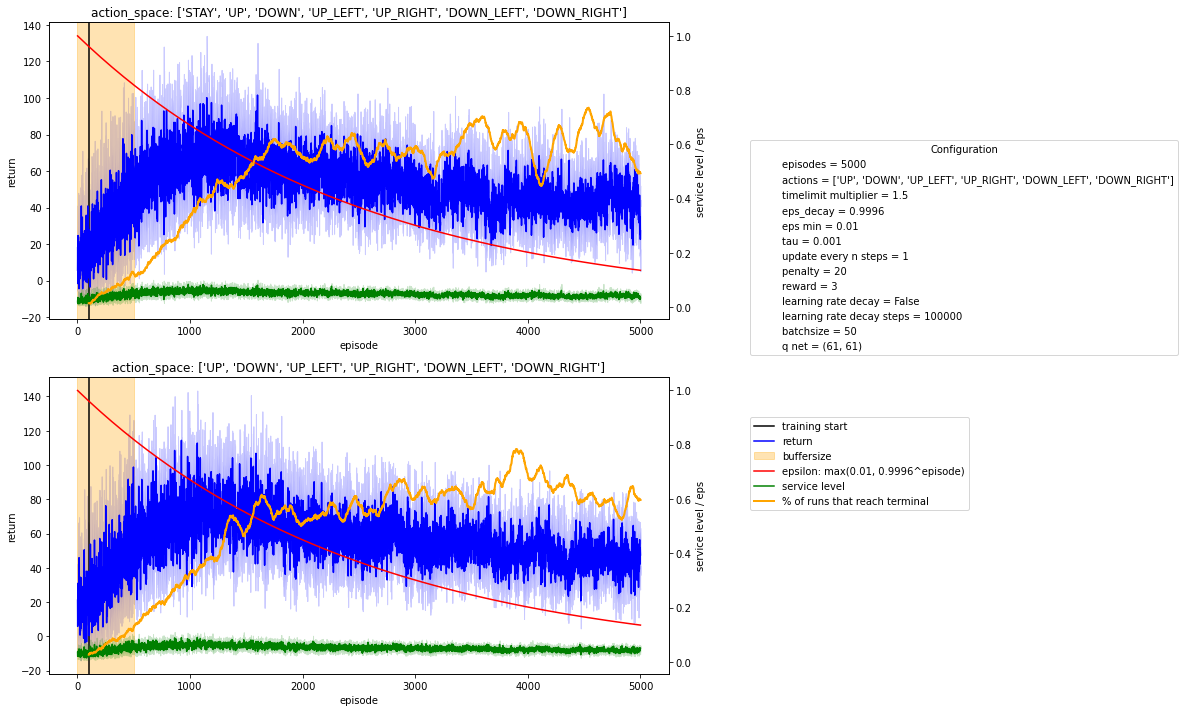

In [4]:
RESULTS = 'search_action_space_experiments_20211220-112049.csv'
COLS = ['episode', 'return', 'service_level', 'lr', 'reached_destination', 'distance', 'duration']

config = {'episodes': episodes, 
          'actions': actions,
          'timelimit multiplier': timelimit,
          'eps_decay': eps_decay,
          'eps min': eps_min,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))
experiments = list(set(results) - set(COLS))

for e in experiments:
    config.pop(e, None) # remove this from configuration legend

n_experiments = len(experiments)
if n_experiments > 2:
    raise NotImplementedError('more than two simultaneous experiments are currently not supported')
elif n_experiments == 2:
    e1 = results[experiments[0]]
    e2 = results[experiments[1]]
    n_e1 = e1.nunique()
    n_e2 = e2.nunique()
    fig, ax = plt.subplots(n_e1, n_e2, figsize=(8*n_e1,5*n_e2))
    ii = 0
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()
        
        if i >= n_e1:
            ii = i // n_e1
            i -= n_e1

        # annotations
        if 'buffersize' in experiments:
            buffersize_i = experiments.index('buffersize')
            ax[ii][i].axvspan(0, name[buffersize_i], color='orange', alpha=.3, label='buffersize')
        else:
            ax[ii][i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[ii][i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[ii][i].twinx()
        ax2 = ax[ii][i].twinx()
        if 'eps_decay_strategy' in experiments:
            epsdecaystrategy_i = experiments.index('eps_decay_strategy')
            eps_decay_strategy = name[epsdecaystrategy_i]
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                epsdecay_i = experiments.index('eps_decay')
                sns.lineplot(x=x_, y=np.maximum(name[epsdecay_i]**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {name}^episode)', legend=False)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[ii][i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[ii][i].set_title(f'{experiments}: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[ii][i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]

elif n_experiments == 1:
    n = results[experiments[0]].nunique()
    fig, ax = plt.subplots(n, figsize=(10,5*n))
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        if 'buffersize' in experiments:
            ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        else:
            ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        if 'eps_decay_strategy' in experiments:
            eps_decay_strategy = name
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                sns.lineplot(x=x_, y=np.maximum(name**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {name}^episode)', legend=False)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', linewidth=2, label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'{experiments[0]}: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

# Single (averaged) agent evaluation

In [21]:
RESULTS = 'average_4_experiments_20211221-054321.csv'

config = {'episodes': episodes, 
          'actions': actions,
          'eps decay strategy': eps_decay_strategy,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'penalty': penalty,
          'learning rate decay': lr_decay,
          'batchsize': batchsize
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(20).mean()
results['service_level_MA'] = results['service_level'].rolling(20).mean()
results['reached_destination_MA'] = results['reached_destination'].rolling(100).mean()

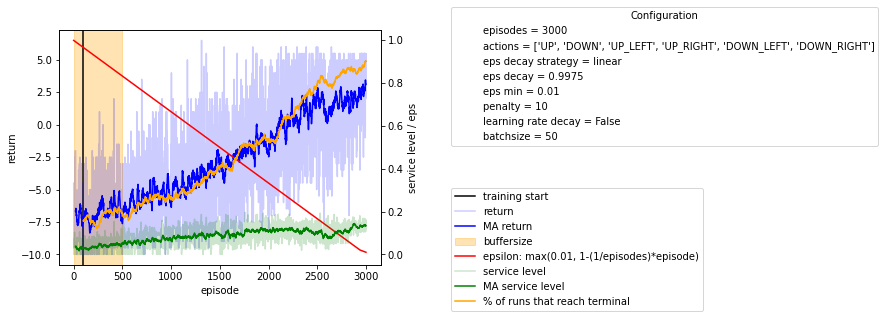

In [22]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
plt.axvline(min_experience, color='black', label='training start')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
if eps_decay_strategy == 'exp':
    sns.lineplot(x=x_, y=np.maximum(0.9994**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
if eps_decay_strategy == 'linear':
    sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
ax_.set_axis_off() # hide this axis

sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

# plt.title('Experiment with tanh activation function in hidden layers')
ax2.set_ylabel('service level / eps')

handles, labels = [(a + b) for a, b in zip(ax.get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.2), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.8), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

## find best of runs

In [1]:
runs = [
    "3000_episodes_returns_20211221-053844.csv",
    "3000_episodes_returns_20211221-054141.csv",
    "3000_episodes_returns_20211221-054248.csv",
    "3000_episodes_returns_20211221-054318.csv"
]

In [6]:
LAST_N = 100

evaluate_results = []

for r in runs:
    run_results = pd.read_csv(os.path.join(DATAPATH, 'returns', r))
    e_cols = list(set(run_results) - set(['service_level', 'episode', 'reached_destination', 'lr', 'return']))
    evaluate_results.append(
        {'run': r,
         'mean_service': run_results["service_level"].mean(), 
         'last_mean_service': run_results["service_level"][-LAST_N:].mean(), 
         'reached_destination': run_results["reached_destination"].mean(), 
         'last_reached_destination': run_results["reached_destination"][-LAST_N:].mean(),
         'experiments': str(run_results.loc[0,e_cols].to_dict())}
    )
    # print(f'Run {r}: \n\tLast runs service level: {run_results["service_level"][-10:].mean()} \n\tLast runs of reaching destination: {run_results["reached_destination"][-10:].mean()}\n\tMean service level: {run_results["service_level"].mean()} \n\tMean of reaching destination: {run_results["reached_destination"].mean()}\n')

In [7]:
evaluate_results = pd.DataFrame.from_records(evaluate_results)
# evaluate_results.groupby('experiments').mean()

In [8]:
evaluate_results

,run,mean_service,last_mean_service,reached_destination,last_reached_destination,experiments
0,3000_episodes_returns_20211221-053844.csv,0.066818,0.126838,0.477000,0.87,{}
1,3000_episodes_returns_20211221-054141.csv,0.087844,0.143692,0.525000,0.98,{}
2,3000_episodes_returns_20211221-054248.csv,0.091392,0.113504,0.445667,0.97,{}
3,3000_episodes_returns_20211221-054318.csv,0.092697,0.141161,0.410667,0.79,{}


In [9]:
# filter out agents that do not reach the destination reliably
evaluate_results_filtered = evaluate_results[evaluate_results['last_reached_destination'] >= 0.8]
# filter out agents that are not stable
# evaluate_results_filtered = evaluate_results_filtered[evaluate_results_filtered['last_mean_service']>=evaluate_results_filtered['mean_service']]
evaluate_results_filtered

,run,mean_service,last_mean_service,reached_destination,last_reached_destination,experiments
0,3000_episodes_returns_20211221-053844.csv,0.066818,0.126838,0.477000,0.87,{}
1,3000_episodes_returns_20211221-054141.csv,0.087844,0.143692,0.525000,0.98,{}
2,3000_episodes_returns_20211221-054248.csv,0.091392,0.113504,0.445667,0.97,{}


In [27]:
evaluate_results_filtered.loc[12, 'run']

"5000_episodes_action_space=['UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_returns_20211220-093336.csv"

# Benchmark best run

In [10]:
BENCHMARK_PATH = 'benchmarks'
# BENCHMARK = '100_episodes_benchmark_20211220-200031.csv' # with stay
BENCHMARK = '100_episodes_benchmark_20211221-160338.csv' # without stay
ROLLING = 1

In [13]:
benchmark_results

,episode,type,reached_destination,service_level,distance,duration,service_level_MA
0,1,BVG,True,0.000000,3443.435838,12.000000,NaN
1,2,BVG,True,0.000000,3443.435838,12.000000,NaN
2,3,BVG,True,0.000000,3443.435838,12.000000,NaN
3,4,BVG,True,0.000000,3443.435838,12.000000,NaN
4,5,BVG,True,0.000000,3443.435838,12.000000,NaN
...,...,...,...,...,...,...,...
195,96,DQN,True,0.181818,7879.118481,15.758237,0.181818
196,97,DQN,True,0.181818,7879.239918,15.758480,0.181818
197,98,DQN,True,0.181818,7879.118481,15.758237,0.181818
198,99,DQN,True,0.181818,7879.118481,15.758237,0.181818


<AxesSubplot:xlabel='episode', ylabel='service_level_MA'>

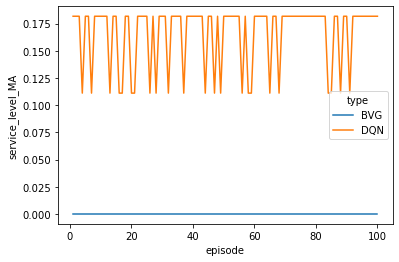

In [14]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK))
# noinspection JupyterPackage
benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
benchmark_results.loc[benchmark_results['type']=='BVG', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='BVG', 'service_level'].rolling(ROLLING).mean()

sns.lineplot(data=benchmark_results, x='episode', y='service_level_MA', hue='type')

In [15]:
print('Service level:')
display(benchmark_results.groupby('type').describe()['service_level'])

print('Distance:')
display(benchmark_results.groupby('type').describe()['distance'])

print('Duration:')
display(benchmark_results.groupby('type').describe()['duration'])

Service level:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
BVG,100.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
DQN,100.0,0.165556,0.029906,0.111111,0.181818,0.181818,0.181818,0.181818


Distance:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
BVG,100.0,3443.435838,4.570383e-13,3443.435838,3443.435838,3443.435838,3443.435838,3443.435838
DQN,100.0,7691.670348,3.448160e+02,7063.920683,7879.118481,7879.118481,7879.239918,7879.239918


Duration:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
BVG,100.0,12.000000,0.000000,12.000000,12.000000,12.000000,12.00000,12.00000
DQN,100.0,15.383341,0.689632,14.127841,15.758237,15.758237,15.75848,15.75848


In [19]:
benchmark_stats = benchmark_results.groupby('type').describe().loc[:,(['service_level', 'distance', 'duration'], ['min', 'mean', 'max'])]
benchmark_stats.loc[:,('distance',['min', 'mean', 'max'])] = benchmark_stats.loc[:,('distance',['min', 'mean', 'max'])] / 1000
benchmark_stats.loc['DQN','destination'] = '{:.0%}'.format(benchmark_results.loc[benchmark_results['type']=='DQN', 'reached_destination'].mean())
benchmark_stats.loc['BVG','destination'] = '100%'

In [20]:
benchmark_stats

service_level                      distance                      \
               min      mean       max       min      mean       max   
type                                                                   
BVG       0.000000  0.000000  0.000000  3.443436  3.443436  3.443436   
DQN       0.111111  0.165556  0.181818  7.063921  7.691670  7.879240   

       duration                      destination  
            min       mean       max              
type                                              
BVG   12.000000  12.000000  12.00000        100%  
DQN   14.127841  15.383341  15.75848        100%

In [36]:
COLUMN_FORMAT = 'lrrrrrrrrr'

latex = benchmark_stats.to_latex(column_format=COLUMN_FORMAT, float_format="{:,.2f}".format, caption='Benchmark configurations', label='tab:benchmarks', position='t')

# multicolumn headers centered
latex = latex.replace('\multicolumn{3}{l}', '\multicolumn{3}{c}')

# rename benchmark to BVG
latex = latex.replace('benchmark (planned)', 'BVG')

print(latex)

\begin{table}[t]
\centering
\caption{Benchmark configurations}
\label{tab:benchmarks}
\begin{tabular}{lrrrrrrrrr}
\toprule
{} & \multicolumn{3}{c}{service\_level} & \multicolumn{3}{c}{distance} & \multicolumn{3}{c}{duration} & destination \\
{} &           min & mean &  max &      min &  mean &   max &      min &  mean & \multicolumn{2}{l}{max} \\
type                &               &      &      &          &       &       &          &       &       &             \\
\midrule
DQN                 &          0.02 & 0.05 & 0.08 &    13.96 & 18.33 & 21.09 &    27.92 & 36.66 & 42.18 &         95\% \\
BVG &          0.03 & 0.03 & 0.03 &    12.36 & 12.36 & 12.36 &    48.00 & 48.00 & 48.00 &        100\% \\
\bottomrule
\end{tabular}
\end{table}



# Code scrapyard

In [12]:
RESULTS = [
    '5000_episodes_returns_20211216-021413.csv',
    '5000_episodes_returns_20211216-030028.csv',
    '5000_episodes_returns_20211216-030903.csv',
    '5000_episodes_returns_20211216-031023.csv',
    '5000_episodes_returns_20211216-034113.csv',
    '5000_episodes_returns_20211216-041024.csv',
    '5000_episodes_returns_20211216-041230.csv',
    '5000_episodes_returns_20211216-041816.csv',
    '5000_episodes_returns_20211216-042849.csv',
    '5000_episodes_returns_20211216-043242.csv',
    '5000_episodes_returns_20211216-044310.csv',
    '5000_episodes_returns_20211216-044529.csv',
    '5000_episodes_returns_20211216-050700.csv',
    '5000_episodes_returns_20211216-050900.csv',
    '5000_episodes_returns_20211216-050953.csv',
    '5000_episodes_returns_20211216-051702.csv',
    '5000_episodes_returns_20211216-052029.csv',
    '5000_episodes_returns_20211216-052151.csv',
    '5000_episodes_returns_20211216-052437.csv',
    '5000_episodes_returns_20211216-054150.csv'
]

re = []

for r in RESULTS:
    re.append(pd.read_csv(os.path.join(DATAPATH, r)))
    
results = pd.concat(re, axis=0, ignore_index=True)
results.to_csv(os.path.join(DATAPATH,'search_reward_experiments_20211216-000000.csv'), index=False)

<AxesSubplot:label='2cc29999-6d10-4bc8-a731-3086deb3bf5c', xlabel='episode', ylabel='reached_destination'>

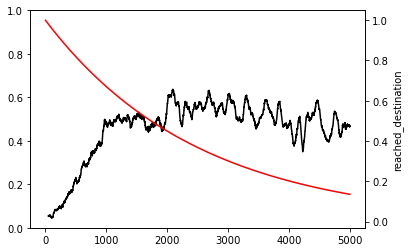

In [57]:
fig, ax = plt.subplots()
# sns.lineplot(ax=ax, data=results, x='episode', y='return', hue='reached_destination')
reached = results.groupby('episode')['reached_destination'].mean().rolling(50).mean().reset_index()
ax2 = ax.twinx()
sns.lineplot(ax=ax2, data=reached, x='episode', y='reached_destination', color='black', alpha=1)
sns.lineplot(x=x_, y=np.maximum(0.9996**x_, eps_min), color='red', ax=ax2)